## Project: Investigate data

For the rest of this week you work on a project of your own. There are no new lessons. Instead
you use everything from the last two weeks on one data set: you read it, clean it, describe it, draw
it, and you say what it can tell us and what it cannot. You work alone, from Tuesday 24 to Friday 27
November, and you plan the days yourself.
You choose one of three data sets (see the last page). Every data set has a second, smaller table
that you can merge with. All three are real data with real problems in them. Nobody has cleaned
them for you, and nobody has told you where the problems are. Finding them is part of the project.

What you hand in - You hand in two things:

1. A notebook (.ipynb) with your code and your text. It must run from the first cell to the last
without errors. Write short markdown cells between the code, so that a reader understands what
you do and why.

2. A short report, one to two pages, as a PDF or a Word file. It is for a reader who has not seen
your notebook (see the end of this document).

##. Requirements

Your project must contain all ten parts below. You decide the order and how much you write for
each. The numbers are only for reference.

1 Read and understand the data
Show how big the table is, what each column contains, and what type it has. Write down,
in a markdown cell, what one row is and which columns you will use.

2 Clean at least three different problems
Find at least three different kinds of problems (for example text, types, dates, duplicates,
or values that cannot be right) and fix them. For each problem, write what it was, how
many rows it touched, and what you did.

3 Handle the missing values
Count what is missing in every column. For at least two columns, decide what to do (keep,
drop, or fill) and write why. Say what the missing values might mean, and not only how
many there are.

4 Merge with the second table
Merge your table with the second table. Check the number of rows before and after the
merge, and check that nothing was lost or doubled.

5 Create new columns
Create at least two new columns that you need for your questions (for example a year, a
category, a ratio, or a group).

6 Group and compare
Make at least three summaries with groupby. Choose them so that they help you answer
your questions.

7 Describe with numbers
Describe at least one column in depth: the middle, the spread, and the outliers. Say
whether mean or median is the better description, and why. Compare two groups or two
columns with a number.

8 Draw at least four charts
Use at least three different chart types. Every chart has a title, labelled axes, and one
sentence below it that says what the reader should see.

9 Answer your own questions
Write two or three questions that you want to answer with the data (the last page has
ideas). Answer each one with numbers and a chart, and write the answer in a sentence.

10 Check the data and the source
Write a short data note: who made the data and when, what is missing, who or what is not
in the data, which columns you cannot trust, and one claim that you would not dare to
make from this data. Look up the source yourself, and write what you do not know about
it.

##. The report

What the report contains. Your question and why it matters. The data (where it comes from and
what one row is). What you did to the data, in a few sentences. Three findings, each with a number
and, if you want, a chart. What the data cannot tell us. A conclusion in two or three sentences.

What makes a good project. Every claim has a number behind it. Every chart has a sentence.
The text says how many rows each choice affects. You write what you do not know, not only what
you know. And your notebook runs from top to bottom.

##. The three data sets

Choose one. Each folder inside data holds the main file and the second table. All three come from
the vega-datasets collection on GitHub, which gathers data sets for teaching. For the origin of the
data itself, check the source yourself (requirement 10).

##. movies

Main table. movies.csv: 3,201 rows, 16 columns. 
One row is one film: 
budget, US and worldwide gross, DVD sales, release date, rating (MPAA), 
running time, distributor, source, genre, creative type, director, 
Rotten Tomatoes and IMDB ratings, IMDB votes.

#. Second table. 

genre_groups.csv: 
puts the 12 genres into 5 groups. It was made for this project.

Merge on Major Genre.

#. Questions to start from.

– Do films with a big budget earn more? Do critics and audiences agree?
– How do the genres differ, in ratings and in money?
– Which columns are almost empty, and what does that do to your answers?

*. Stuck? 
- Read the error message from the bottom up, print the data you are working with, 
  and look at the lesson notebooks. Then ask.

## movies

In [22]:
import pandas as pd

movies = pd.read_csv('data/movies.csv')   # Main table
movies.shape      # Show how big the table is

(3201, 16)

In [23]:
import pandas as pd

genre_groups = pd.read_csv('data/genre_groups.csv')    # Second table
genre_groups.shape         # Show how big the table is

(12, 2)

In [24]:
movies.info()  # Show how big the MAIN table is, what each column contains, and what type it has.

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   float64
 15

In [25]:
genre_groups.info()  # Show how big the SECOND table is, what each column contains, and what type it has.

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Major Genre  12 non-null     str  
 1   Genre group  12 non-null     str  
dtypes: str(2)
memory usage: 324.0 bytes


In [26]:
movies.head()  # What each column contains - MAIN table

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


In [27]:
genre_groups.head()    # What each column contains - SECOND table

,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music


In [28]:
movies.dtypes.value_counts()

str        8
float64    8
Name: count, dtype: int64

In [29]:
genre_groups.dtypes.value_counts()

str    2
Name: count, dtype: int64

## 1. All together för task 1: 
Read and understand the data
Show how big the table is, what each column contains, and what type it has. Write down,
in a markdown cell, what one row is and which columns you will use.

In [3]:
# 1.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

movies = pd.read_csv('data/movies.csv')
genre_groups = pd.read_csv('data/genre_groups.csv')

print("Movies shape:", movies.shape)
print("Genre groups shape:", genre_groups.shape)
print("\n--- Movies info ---")
movies.info()
print("\n--- First 5 rows ---")
display(movies.head())
print("\n--- Genre groups ---")
display(genre_groups)

Movies shape: (3201, 16)
Genre groups shape: (12, 2)

--- Movies info ---
<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 n

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0



--- Genre groups ---


,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music
5,Action,Action & adventure
6,Adventure,Action & adventure
7,Western,Action & adventure
8,Thriller/Suspense,Thriller & horror
9,Horror,Thriller & horror


# 2 Clean at least three different problems

Find at least three different kinds of problems (for example text, types, dates, duplicates,
or values that cannot be right) and fix them. For each problem, write what it was, how
many rows it touched, and what you did.

In [4]:
# 2.

movies_clean = movies.copy()

# Problem 1: Parse Release Date to datetime and inspect/handle future dates

movies_clean['Release Date_dt'] = pd.to_datetime(movies_clean['Release Date'], errors='coerce')
future_mask = movies_clean['Release Date_dt'] > pd.Timestamp('2026-11-27')

print("Future / suspect release dates count:", future_mask.sum())
display(movies_clean.loc[future_mask, ['Title', 'Release Date', 'Release Date_dt']])

# Decision: set suspect future release dates to NaT so release_year isn't distorted
movies_clean.loc[future_mask, 'Release Date_dt'] = pd.NaT


# Problem 2: Strip whitespace / standardize text in Title and Major Genre

for col in ['Title', 'Major Genre', 'MPAA Rating', 'Distributor', 'Source', 'Creative Type', 'Director']:
    before_sample = movies_clean[col].dropna().astype(str)
    trimmed = before_sample.str.strip()
    changed = (before_sample != trimmed).sum()
    if changed > 0:
        print(f"Trimmed whitespace in {col}: {changed} rows")
    movies_clean[col] = movies_clean[col].astype('string').str.strip()

# Problem 3: Check duplicate rows (exact duplicates and duplicate Titles)
exact_dups = movies_clean.duplicated().sum()
title_dups = movies_clean.duplicated(subset=['Title'], keep=False).sum()
print("Exact duplicate rows:", exact_dups)
print("Rows involved in repeated Titles:", title_dups)
movies_clean = movies_clean.drop_duplicates()

Future / suspect release dates count: 16


,Title,Release Date,Release Date_dt
9,Duel in the Sun,Dec 31 2046,2046-12-31
16,Wilson,Aug 01 2044,2044-08-01
33,42nd Street,Mar 09 2033,2033-03-09
90,The Best Years of Our Lives,Nov 21 2046,2046-11-21
174,"Charge of the Light Brigade, The",Oct 20 2036,2036-10-20
221,Cat People,Nov 16 2042,2042-11-16
337,Fantasia,Nov 13 2040,2040-11-13
382,A Guy Named Joe,Dec 24 2043,2043-12-24
400,Gone with the Wind,Dec 15 2039,2039-12-15
412,How Green Was My Valley,Oct 28 2041,2041-10-28


Exact duplicate rows: 0
Rows involved in repeated Titles: 48


## 3 Handle the missing values

Count what is missing in every column. For at least two columns, decide what to do (keep,
drop, or fill) and write why. Say what the missing values might mean, and not only how
many there are.

In [5]:
# 3.

missing_summary = pd.DataFrame({
    'missing_count': movies_clean.isna().sum(),
    'missing_pct': (movies_clean.isna().mean() * 100).round(1)
}).sort_values('missing_count', ascending=False)

display(missing_summary)

,missing_count,missing_pct
US DVD Sales,2637,82.4
Running Time min,1992,62.2
Director,1331,41.6
Rotten Tomatoes Rating,880,27.5
MPAA Rating,605,18.9
Creative Type,446,13.9
Source,365,11.4
Major Genre,275,8.6
Distributor,232,7.2
IMDB Votes,213,6.7


## 3.+ Example decisions for specific columns:

- 'US DVD Sales': round 82% missing -> KEEP as NaN ( filling with 0 would artificially drag down averages).
- 'Major Genre': missing for about 280 rows -> KEEP as NaN (or label separately only when
   needed) so we don't invent genres, while knowing uncategorized films won't appear in
   genre-only summaries.

## 4 Merge with the second table

Merge your table with the second table. 
Check the number of rows before and after the merge, and check that nothing was lost or doubled.

In [ ]:
# 4.Merge with the second table

rows_before = len(movies_clean)

merged = movies_clean.merge(genre_groups, on='Major Genre', how='left')
rows_after = len(merged)

print("Rows before merge:", rows_before)
print("Rows after merge:", rows_after)
print("Rows with missing Genre group after merge:", merged['Genre group'].isna().sum())
print("Unmatched non-null Major Genre values:", merged.loc[merged['Major Genre'].notna() & merged['Genre group'].isna(), 'Major Genre'].unique())
movies_clean.shape

Rows before merge: 3201
Rows after merge: 3201
Rows with missing Genre group after merge: 275
Unmatched non-null Major Genre values: []


(3201, 17)

In [37]:
# Additional TEST for 4.
print("Columns after merge:", merged.shape[1])
print(merged[['Title', 'Major Genre', 'Genre group']].dropna(subset=['Major Genre']).head(10))

Columns after merge: 18
                         Title Major Genre     Genre group
1       First Love, Last Rites       Drama           Drama
2   I Married a Strange Person      Comedy  Comedy & music
3         Let's Talk About Sex      Comedy  Comedy & music
4                         Slam       Drama           Drama
7                      Foolish      Comedy  Comedy & music
11                     Oliver!     Musical  Comedy & music
19                12 Angry Men       Drama           Drama
20              Twelve Monkeys       Drama           Drama
21                        1776       Drama           Drama
22                        1941      Comedy  Comedy & music


## 5 Create new columns

Create at least two new columns that you need for your questions 
(for example a year, a category, a ratio, or a group).

In [7]:
## 5 Create new columns

import numpy as np
import pandas as pd

# Ensure `merged` exists (build from `movies_clean` and `genre_groups` if not yet in memory)
if 'merged' not in globals():
    merged = movies_clean.merge(genre_groups, on='Major Genre', how='left')

# Ensure `Release Date_dt` exists before extracting `.dt.year`
if 'Release Date_dt' not in merged.columns:
    merged['Release Date_dt'] = pd.to_datetime(merged['Release Date'], errors='coerce')

# Release year from cleaned date
merged['release_year'] = merged['Release Date_dt'].dt.year

# Normalized Rotten Tomatoes rating on a 0-10 scale (since RT is 0-100 and IMDB is 0-10)
merged['rt_rating_10'] = merged['Rotten Tomatoes Rating'] / 10.0
merged['imdb_minus_rt10'] = merged['IMDB Rating'] - merged['rt_rating_10']

# Worldwide gross vs. production budget difference and ratio (where budget > 0)
merged['gross_minus_budget'] = merged['Worldwide Gross'] - merged['Production Budget']
merged['gross_to_budget_ratio'] = np.where(
    merged['Production Budget'] > 0,
    merged['Worldwide Gross'] / merged['Production Budget'],
    np.nan
)

print(
    merged[
        [
            'Title',
            'release_year',
            'rt_rating_10',
            'imdb_minus_rt10',
            'gross_minus_budget',
            'gross_to_budget_ratio',
        ]
    ].head()
)

                        Title  release_year  rt_rating_10  imdb_minus_rt10  \
0              The Land Girls        1998.0           NaN              NaN   
1      First Love, Last Rites        1998.0           NaN              NaN   
2  I Married a Strange Person        1998.0           NaN              NaN   
3        Let's Talk About Sex        1998.0           1.3              NaN   
4                        Slam        1998.0           6.2             -2.8   

   gross_minus_budget  gross_to_budget_ratio  
0          -7853917.0               0.018260  
1           -289124.0               0.036253  
2            -46866.0               0.812536  
3             73615.0               1.245383  
4             87521.0               1.087521  


## 6 Group and compare

Make at least three summaries with groupby. 
Choose them so that they help you answer your questions.

In [8]:
## 6 Group and compare

# Summary 1: Genre group - count, median budget, median worldwide gross, median IMDB & RT (0-10)

by_genre_group = (
    merged.groupby('Genre group', dropna=False)
    .agg(
        n_films=('Title', 'count'),
        median_budget=('Production Budget', 'median'),
        median_ww_gross=('Worldwide Gross', 'median'),
        median_imdb=('IMDB Rating', 'median'),
        median_rt10=('rt_rating_10', 'median')
    )
    .sort_values('median_ww_gross', ascending=False)
)
display(by_genre_group.round(2))

# Summary 2: Major Genre (filtered to groups with at least 30 films for reliability)
by_major_genre = (
    merged.groupby('Major Genre', dropna=False)
    .agg(
        n_films=('Title', 'count'),
        median_budget=('Production Budget', 'median'),
        median_ww_gross=('Worldwide Gross', 'median'),
        avg_imdb=('IMDB Rating', 'mean'),
        avg_rt10=('rt_rating_10', 'mean')
    )
)
display(by_major_genre[by_major_genre['n_films'] >= 30].sort_values('median_ww_gross', ascending=False).round(2))

# Summary 3: MPAA Rating comparison
by_mpaa = (
    merged.groupby('MPAA Rating', dropna=False)
    .agg(
        n_films=('Title', 'count'),
        median_budget=('Production Budget', 'median'),
        median_ww_gross=('Worldwide Gross', 'median'),
        median_imdb=('IMDB Rating', 'median')
    )
    .sort_values('n_films', ascending=False)
)
display(by_mpaa.round(2))

,n_films,median_budget,median_ww_gross,median_imdb,median_rt10
Genre group,,,,,
Action & adventure,730,45000000.0,88862318.0,6.40,5.40
Thriller & horror,457,18750000.0,34939606.5,6.10,3.90
Comedy & music,901,19000000.0,32863003.0,6.00,4.70
Drama,789,15000000.0,19317765.0,6.90,6.80
NaN,275,3900000.0,3000000.0,6.55,8.40
Non-fiction,48,2000000.0,2716318.0,7.40,8.25


,n_films,median_budget,median_ww_gross,avg_imdb,avg_rt10
Major Genre,,,,,
Adventure,274,56000000.0,132999905.5,6.35,5.86
Action,420,44500000.0,78850000.0,6.11,4.82
Thriller/Suspense,238,27000000.0,40147042.0,6.36,4.76
Romantic Comedy,137,23000000.0,38177966.0,5.87,4.30
Musical,53,12500000.0,34600000.0,6.45,6.80
Comedy,675,20000000.0,33675913.5,5.85,4.78
Horror,219,13000000.0,33606409.0,5.68,4.12
Drama,789,15000000.0,19317765.0,6.77,6.31
Western,36,19500000.0,15350888.0,6.84,6.50


,n_films,median_budget,median_ww_gross,median_imdb
MPAA Rating,,,,
R,1194,16000000.0,22139590.0,6.60
PG-13,865,35000000.0,56262662.0,6.20
<NA>,605,7000000.0,18180509.5,6.70
PG,354,32250000.0,60306579.5,6.10
Not Rated,93,2250000.0,443044.5,6.70
G,79,32000000.0,109862682.0,6.30
NC-17,8,1500000.0,10708387.5,6.45
Open,2,2600000.0,4264472.0,7.85


## 7 Describe with numbers

Describe at least one column in depth: the middle, the spread, and the outliers. Say
whether mean or median is the better description, and why. Compare two groups or two
columns with a number.

In [9]:
## 7 Describe with numbers

budget_series = merged['Production Budget'].dropna()

print("Count:", budget_series.count())
print("Mean:", round(budget_series.mean(), 0))
print("Median (50%):", round(budget_series.median(), 0))
print("25th percentile (Q1):", round(budget_series.quantile(0.25), 0))
print("75th percentile (Q3):", round(budget_series.quantile(0.75), 0))
print("IQR (Q3 - Q1):", round(budget_series.quantile(0.75) - budget_series.quantile(0.25), 0))
print("Min / Max:", budget_series.min(), "/", budget_series.max())

# Compare two groups or two columns with a number:
# e.g., median worldwide gross for big-budget (>= median budget) vs lower-budget (< median budget)
med_b = budget_series.median()
high_b = merged.loc[merged['Production Budget'] >= med_b, 'Worldwide Gross'].median()
low_b = merged.loc[merged['Production Budget'] < med_b, 'Worldwide Gross'].median()
print(f"Median Worldwide Gross (>= median budget): {high_b:,.0f}")
print(f"Median Worldwide Gross (< median budget):  {low_b:,.0f}")

Count: 3200
Mean: 31069171.0
Median (50%): 20000000.0
25th percentile (Q1): 6575000.0
75th percentile (Q3): 42000000.0
IQR (Q3 - Q1): 35425000.0
Min / Max: 218.0 / 300000000.0
Median Worldwide Gross (>= median budget): 73,371,916
Median Worldwide Gross (< median budget):  11,000,000


## 8 Draw at least four charts

Use at least three different chart types. 
Every chart has a title, labelled axes, and one sentence below it that says what the reader should see.

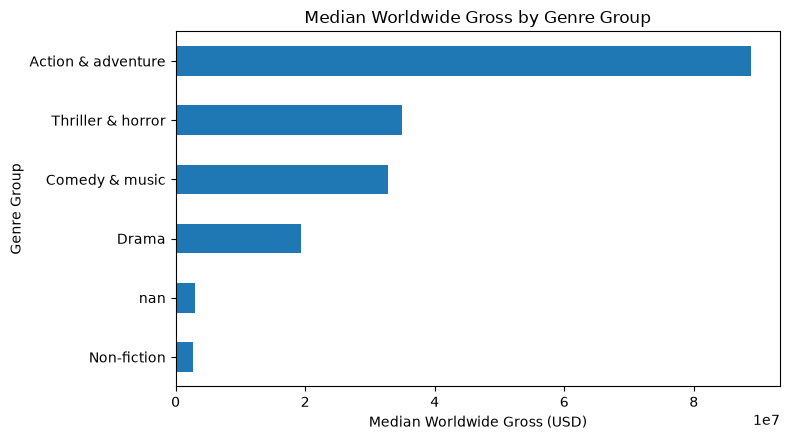

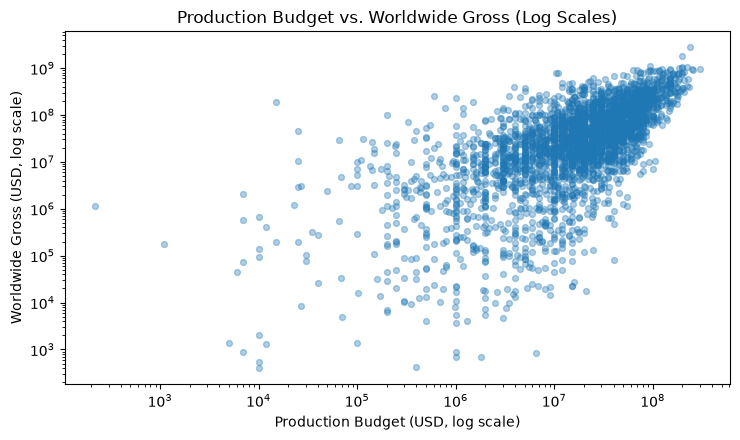

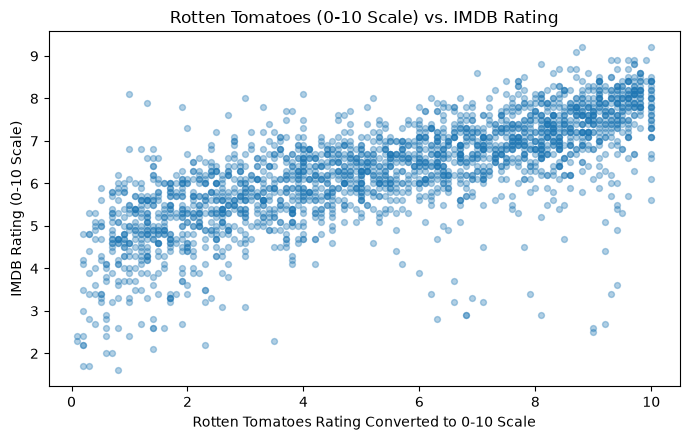

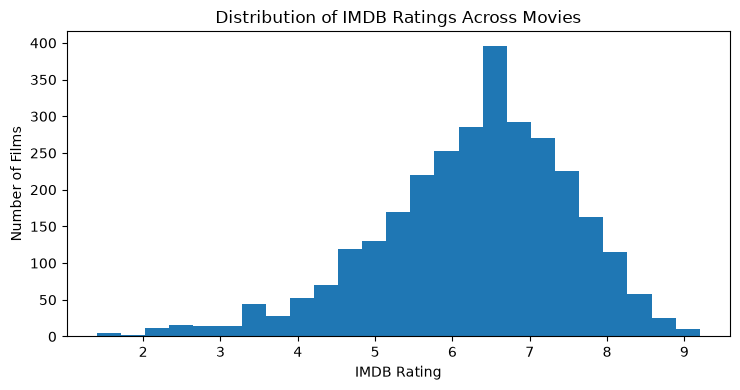

In [ ]:
## 8 Draw at least four charts

# Chart 1 (Bar chart): Median Worldwide Gross by Genre group

ax = by_genre_group['median_ww_gross'].dropna().sort_values().plot(kind='barh', figsize=(8, 4.5))
ax.set_title('Median Worldwide Gross by Genre Group')
ax.set_xlabel('Median Worldwide Gross (USD)')
ax.set_ylabel('Genre Group')
plt.tight_layout()
plt.show()

#****************************


# Chart 2 (Scatter plot): Production Budget vs. Worldwide Gross (log scale helps readable spread)

valid_fin = merged.dropna(subset=['Production Budget', 'Worldwide Gross'])
valid_fin = valid_fin[(valid_fin['Production Budget'] > 0) & (valid_fin['Worldwide Gross'] > 0)]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(valid_fin['Production Budget'], valid_fin['Worldwide Gross'], alpha=0.35, s=18)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Production Budget vs. Worldwide Gross (Log Scales)')
ax.set_xlabel('Production Budget (USD, log scale)')
ax.set_ylabel('Worldwide Gross (USD, log scale)')
plt.tight_layout()
plt.show()

#***********************


# Chart 3 (Scatter / comparison): IMDB Rating vs. Rotten Tomatoes Rating (0-10 scale)

ratings_df = merged.dropna(subset=['IMDB Rating', 'rt_rating_10'])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(ratings_df['rt_rating_10'], ratings_df['IMDB Rating'], alpha=0.35, s=18)
ax.set_title('Rotten Tomatoes (0-10 Scale) vs. IMDB Rating')
ax.set_xlabel('Rotten Tomatoes Rating Converted to 0-10 Scale')
ax.set_ylabel('IMDB Rating (0-10 Scale)')
plt.tight_layout()
plt.show()

#*******************

# Chart 4 (Histogram): Distribution of IMDB Ratings

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(merged['IMDB Rating'].dropna(), bins=25)
ax.set_title('Distribution of IMDB Ratings Across Movies')
ax.set_xlabel('IMDB Rating')
ax.set_ylabel('Number of Films')
plt.tight_layout()
plt.show()

# 8 - 4 Charts explanation with one sencence:

#.Chart 1:
Genre groups with blockbuster action/adventure or family titles typically 
achieve higher median worldwide grosses than documentary or drama-heavy groups.

#.Chart 2:
Higher production budgets generally align with higher worldwide box office gross, 
though spread is wide at every budget level. (More money-more sucess - generally)


#.Chart 3:
Critics (Rotten Tomatoes) and general audience users (IMDB) follow a positive general trend,
but scores for individual films often diverge noticeably.

#.Chart 4: 
Most rated films cluster moderately between roughly 5.5 and 7.5 on IMDB, 
with fewer very low or very high scores.


## 9 Answer your own questions

Write two or three questions that you want to answer with the data (the last page has ideas). 
Answer each one with numbers and a chart, and write the answer in a sentence.
*---------------------

## Question 9.1: Do films with a larger production budget earn more worldwide gross?


=== Question 9.1: Production Budget vs. Worldwide Gross ===
Films analyzed (positive budget & gross): 3146
Median Production Budget threshold: $20,000,000
Median Worldwide Gross (>= median budget, n=1601): $75,066,323
Median Worldwide Gross (< median budget, n=1545):  $11,549,034
Correlation (log10 budget vs. log10 gross): 0.65


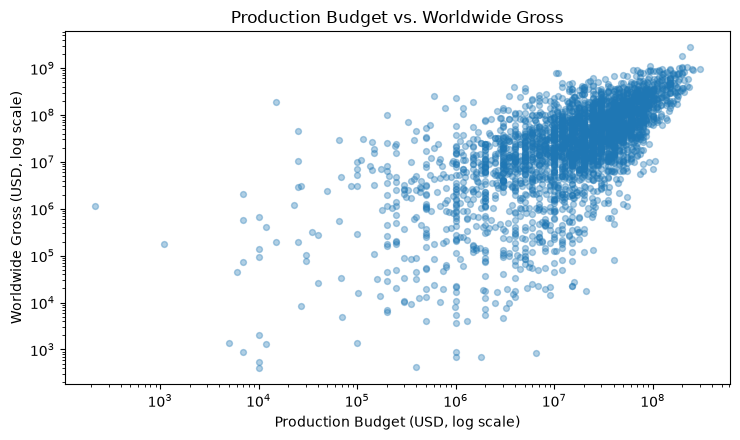

In [21]:
# ==============================================================================
# Question 9.1: Do films with a larger production budget earn more worldwide gross?
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# Safe fallback if earlier cells have not yet been executed in this session
if 'merged' not in globals():
    movies_raw = pd.read_csv('data/movies.csv')
    genre_groups = pd.read_csv('data/genre_groups.csv')

    movies_clean = movies_raw.copy()
    for col in ['Title', 'Major Genre', 'MPAA Rating', 'Distributor', 'Source', 'Creative Type', 'Director']:
        if col in movies_clean.columns:
            movies_clean[col] = movies_clean[col].astype('string').str.strip()

    movies_clean['Release Date_dt'] = pd.to_datetime(movies_clean['Release Date'], errors='coerce')
    future_mask = movies_clean['Release Date_dt'] > pd.Timestamp('2026-11-27')
    movies_clean.loc[future_mask, 'Release Date_dt'] = pd.NaT
    movies_clean = movies_clean.drop_duplicates()

    merged = movies_clean.merge(genre_groups, on='Major Genre', how='left')
    merged['release_year'] = merged['Release Date_dt'].dt.year
    merged['rt_rating_10'] = merged['Rotten Tomatoes Rating'] / 10.0
    merged['imdb_minus_rt10'] = merged['IMDB Rating'] - merged['rt_rating_10']
    merged['gross_minus_budget'] = merged['Worldwide Gross'] - merged['Production Budget']
    merged['gross_to_budget_ratio'] = np.where(
        merged['Production Budget'] > 0,
        merged['Worldwide Gross'] / merged['Production Budget'],
        np.nan
    )

# ==============================================================================
# Question 1: Do films with a larger production budget earn more worldwide gross?
# ==============================================================================
fin_df = merged.dropna(subset=['Production Budget', 'Worldwide Gross'])
fin_df = fin_df[(fin_df['Production Budget'] > 0) & (fin_df['Worldwide Gross'] > 0)]

med_budget = fin_df['Production Budget'].median()
big_budget = fin_df[fin_df['Production Budget'] >= med_budget]
small_budget = fin_df[fin_df['Production Budget'] < med_budget]

print("=== Question 9.1: Production Budget vs. Worldwide Gross ===")
print(f"Films analyzed (positive budget & gross): {len(fin_df)}")
print(f"Median Production Budget threshold: ${med_budget:,.0f}")
print(f"Median Worldwide Gross (>= median budget, n={len(big_budget)}): ${big_budget['Worldwide Gross'].median():,.0f}")
print(f"Median Worldwide Gross (< median budget, n={len(small_budget)}):  ${small_budget['Worldwide Gross'].median():,.0f}")
print(f"Correlation (log10 budget vs. log10 gross): {np.log10(fin_df['Production Budget']).corr(np.log10(fin_df['Worldwide Gross'])):.2f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(fin_df['Production Budget'], fin_df['Worldwide Gross'], alpha=0.35, s=18)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_title('Production Budget vs. Worldwide Gross')
ax.set_xlabel('Production Budget (USD, log scale)')
ax.set_ylabel('Worldwide Gross (USD, log scale)')
plt.tight_layout()
plt.show()

## Answer: Question 9.1: Do films with a larger production budget earn more worldwide gross?

- Films with higher production budgets tend to earn higher worldwide gross, 
  though actual box office outcomes vary widely at every budget level.

- Answer in one sentence:
  Films with a production budget at or above the median earn a substantially higher median worldwide gross 
  than films below the median budget, though a large budget does not guarantee high returns for every film.

## Question 9.2: Do critics (Rotten Tomatoes) and audiences (IMDB) agree?


=== Question 9.2: Rotten Tomatoes (0-10) vs. IMDB Rating ===
Films with both ratings: 2260
Pearson correlation: 0.74
Median IMDB rating: 6.40 | Median RT (0-10): 5.50
Median absolute difference between IMDB and RT (0-10): 1.60 points


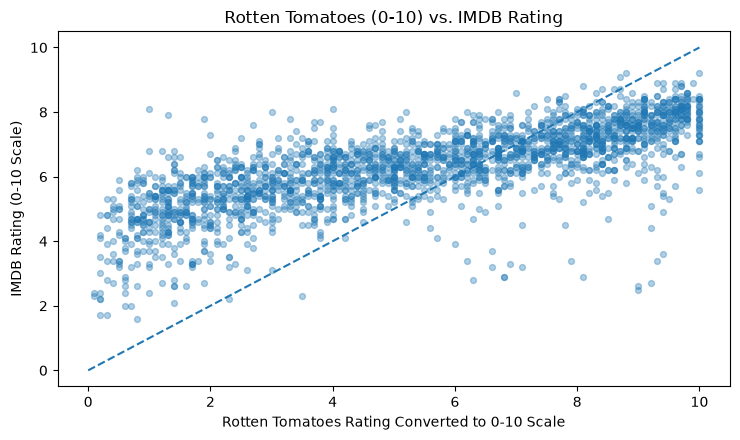

In [20]:
# ==============================================================================
# Question 2: Do critics (Rotten Tomatoes) and audiences (IMDB) agree?
# ==============================================================================

both_ratings = merged.dropna(subset=['rt_rating_10', 'IMDB Rating']).copy()
both_ratings['abs_diff'] = (both_ratings['IMDB Rating'] - both_ratings['rt_rating_10']).abs()

print("\n=== Question 9.2: Rotten Tomatoes (0-10) vs. IMDB Rating ===")
print(f"Films with both ratings: {len(both_ratings)}")
print(f"Pearson correlation: {both_ratings['rt_rating_10'].corr(both_ratings['IMDB Rating']):.2f}")
print(f"Median IMDB rating: {both_ratings['IMDB Rating'].median():.2f} | Median RT (0-10): {both_ratings['rt_rating_10'].median():.2f}")
print(f"Median absolute difference between IMDB and RT (0-10): {both_ratings['abs_diff'].median():.2f} points")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(both_ratings['rt_rating_10'], both_ratings['IMDB Rating'], alpha=0.35, s=18)
ax.plot([0, 10], [0, 10], linestyle='--')
ax.set_title('Rotten Tomatoes (0-10) vs. IMDB Rating')
ax.set_xlabel('Rotten Tomatoes Rating Converted to 0-10 Scale')
ax.set_ylabel('IMDB Rating (0-10 Scale)')
plt.tight_layout()
plt.show()

## Answer: Question 9.2: Do critics (Rotten Tomatoes) and audiences (IMDB) agree?

- Critics and IMDB users show a positive overall relationship, yet many individual films 
  sit noticeably above or below the diagonal agreement line.

- Answer in one sentence:
  Rotten Tomatoes scores (on a 0-10 scale) and IMDB ratings correlate positively overall,
  but individual films frequently show noticeable gaps between critical and audience scores. 

## Question 9.3: How do Genre groups differ in IMDB rating and worldwide gross?


=== Question 9.3: Genre Group Differences ===
                    n_films  median_imdb  median_ww_gross
Genre group                                              
Action & adventure      730          6.4       88862318.0
Thriller & horror       457          6.1       34939606.0
Comedy & music          901          6.0       32863003.0
Drama                   789          6.9       19317765.0
Non-fiction              48          7.4        2716318.0


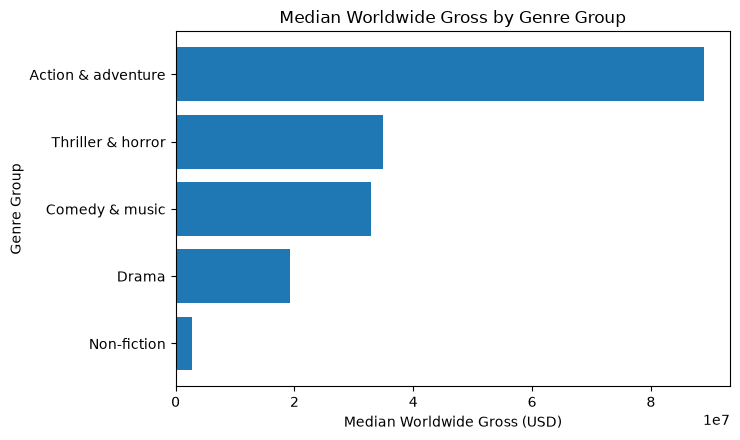

In [19]:
# ==============================================================================
# Question 3: How do Genre groups differ in IMDB rating and worldwide gross?
# ==============================================================================

genre_summary = (
    merged.dropna(subset=['Genre group'])
    .groupby('Genre group')
    .agg(
        n_films=('Title', 'count'),
        median_imdb=('IMDB Rating', 'median'),
        median_ww_gross=('Worldwide Gross', 'median')
    )
    .sort_values('median_ww_gross', ascending=False)
)

print("\n=== Question 9.3: Genre Group Differences ===")
print(genre_summary.round({'median_imdb': 2, 'median_ww_gross': 0}))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(genre_summary.index[::-1], genre_summary['median_ww_gross'].iloc[::-1])
ax.set_title('Median Worldwide Gross by Genre Group')
ax.set_xlabel('Median Worldwide Gross (USD)')
ax.set_ylabel('Genre Group')
plt.tight_layout()
plt.show()

## Answer: Question 9.3: How do Genre groups differ in IMDB rating and worldwide gross?

- Genre groups differ substantially in median worldwide gross, with broad commercial groups 
  leading while smaller or drama-heavy groups earn less.

- Answer in one sentence:
  Genre groups differ much more in median worldwide gross than in median IMDB rating,
  which stays relatively close across groups. 

## 10 Check the data and the source

Write a short data note: 
1. Who made the data and when, 
2. What is missing, 
3. Who or what is not in the data, 
4. Which columns you cannot trust, and 
5. One claim that you would not dare to make from this data. 

6. Look up the source yourself, and write what you do not know about it.

## Answer:

1. Who made the data and when:

 - The teaching dataset comes from the open-source `vega-datasets` 
   repository on GitHub (`movies.json` / `movies.csv`, 3,201 rows and 16 columns), '
   maintained by Vega / UW data visualization contributors as an example dataset for teaching and visualization. 
   The companion `genre_groups.csv` table (12 rows, 2 columns) was created specifically for this project 
   to map `Major Genre` into five broader groups. 
   Looking up the `vega-datasets` documentation shows that the repository packages educational example datasets 
   alongside metadata, while the underlying movie records combine film release, box office, 
   and rating fields (such as Rotten Tomatoes and IMDB).


2. What is missing:

- Missingness is uneven across columns—for example, 
  `US DVD Sales` is missing for 2,637 of 3,201 rows (~82.4%), 
  `Running Time min` is missing for 1,992 rows (~62.2%), and 
  `Director` is missing for 1,331 rows (~41.6%),
   
   whereas `Release Date` has 0 missing strings and 
   `Title` and `Production Budget` are missing in only 1 row each (3,200 non-null). 
   
   More broadly, the table lacks post-release context such as inflation adjustments, 
   marketing/P&A spend, streaming/VOD revenue, and exact rating timestamps.


3. Who or what is not in the data:

- Films without entries in this compiled catalog are absent—such as many micro-budget or non-theatrical releases,
  local/regional cinema outside mainstream English-language/theatrical tracking, unrated or obscure titles 
  with no IMDB/Rotten Tomatoes coverage, and any movies released after the cutoff of the source snapshot.


4. Which columns you cannot trust blindly:

- `US DVD Sales` and `Running Time min`: high missingness (~82% and ~62%) means averages 
   or totals can be heavily distorted by selection/reporting gaps if treated as complete.

-  `Release Date`: contains raw date strings that include anomalous or suspect future dates when parsed, 
   so it cannot be trusted without date validation/cleaning.

-  `Rotten Tomatoes Rating` vs. `IMDB Rating`: they sit on different scales (`0–100` integer vs. `0–10` score) and reflect different rater pools and aggregation rules, making raw side-by-side comparisons misleading without normalization and caveats.


5. One claim I would not dare to make:

- I would not claim from this dataset that spending more on `Production Budget` "causes" 
  a film to earn higher `Worldwide Gross` or guarantees box-office success, 
  nor that these averages represent all movies ever made.

6. What I do not know about the source:

- Even after checking `vega-datasets`, I do not know the exact original scraping or compilation pipeline 
  used to assemble every field in `movies.csv`, the exact date when the underlying movie figures were harvested, 
  whether missing financial figures mean "not tracked," "zero," or "undisclosed," 
  or what exact rules determined which 3,201 films entered the table.